# Ćwiczenia do wykładu 2 – Próbkowanie, aliasing i kwantyzacja

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Zadanie 1. Numer próbki a czas

fs   N    Ts [s]    t[7] [s]  t[-1] [s]  fs/f
12   24   0.0833    0.5833    1.9167     4
24   48   0.0417    0.2917    1.9583     8
48   96   0.0208    0.1458    1.9792     16
odstęp w t_zle = 0.087  1/12 = 0.0833


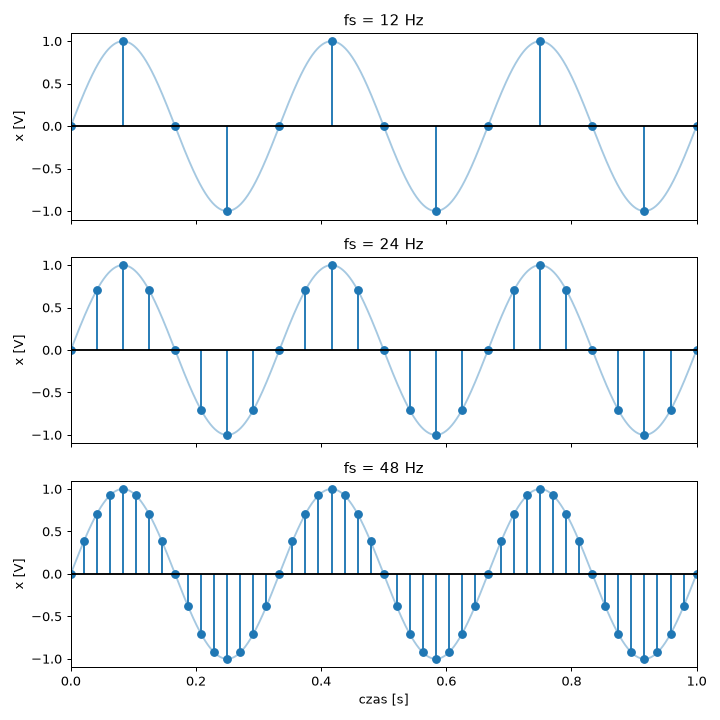

In [2]:
f = 3          # częstotliwość sygnału [Hz]
D = 2          # czas zapisu [s]
t_g = np.linspace(0, D, 4001)            # gęsta siatka – tylko do rysowania

fig, osie = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
print("fs   N    Ts [s]    t[7] [s]  t[-1] [s]  fs/f")
for ax, fs in zip(osie, [12, 24, 48]):
    N = int(D * fs)                      # liczba próbek
    t = np.arange(N) / fs                # chwile pomiaru
    x = np.sin(2 * np.pi * f * t)        # próbki
    print(f"{fs:<4} {N:<4} {1/fs:.4f}    {t[7]:.4f}    {t[-1]:.4f}     {fs/f:g}")
    ax.plot(t_g, np.sin(2 * np.pi * f * t_g), alpha=0.4)
    ax.stem(t, x, basefmt="k-")
    ax.set_xlim(0, 1)
    ax.set_title(f"fs = {fs} Hz")
    ax.set_ylabel("x [V]")
osie[-1].set_xlabel("czas [s]")
plt.tight_layout()
plt.savefig("zadanie1.png")
plt.show()

# pułapka: linspace dołącza punkt końcowy
t_zle = np.linspace(0, D, int(D * 12))
print("odstęp w t_zle =", round(t_zle[1] - t_zle[0], 4), " 1/12 =", round(1 / 12, 4))

## Zadanie 2. Różne częstotliwości, te same próbki

D = 2 s
  2 Hz: True False   f - k*fs = 2 - 0*12 = +2 Hz
  10 Hz: False True   f - k*fs = 10 - 1*12 = -2 Hz
  14 Hz: True False   f - k*fs = 14 - 1*12 = +2 Hz
  26 Hz: True False   f - k*fs = 26 - 2*12 = +2 Hz
D = 20 s
  2 Hz: True False   f - k*fs = 2 - 0*12 = +2 Hz
  10 Hz: False True   f - k*fs = 10 - 1*12 = -2 Hz
  14 Hz: True False   f - k*fs = 14 - 1*12 = +2 Hz
  26 Hz: True False   f - k*fs = 26 - 2*12 = +2 Hz


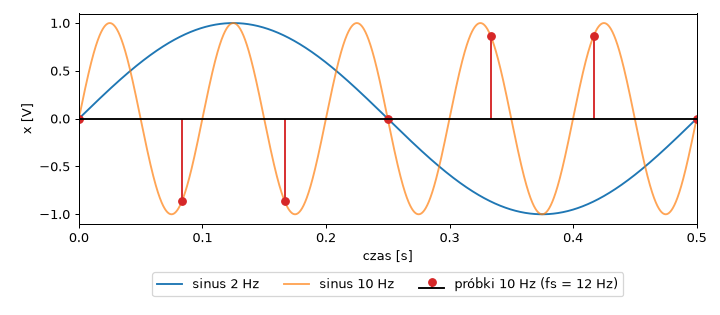

In [3]:
fs = 12
for D in [2, 20]:
    t = np.arange(int(D * fs)) / fs
    x2 = np.sin(2 * np.pi * 2 * t)            # wzorzec: sinus 2 Hz
    print("D =", D, "s")
    for f in [2, 10, 14, 26]:
        x = np.sin(2 * np.pi * f * t)
        takie_same = np.allclose(x, x2, atol=1e-10)
        przeciwne = np.allclose(x, -x2, atol=1e-10)
        k = round(f / fs)
        print(f"  {f} Hz: {takie_same} {przeciwne}   f - k*fs = {f} - {k}*{fs} = {f - k*fs:+d} Hz")

t = np.arange(int(2 * fs)) / fs
t_g = np.linspace(0, 0.5, 2001)
plt.figure(figsize=(8, 3.5))
plt.plot(t_g, np.sin(2 * np.pi * 2 * t_g), label="sinus 2 Hz")
plt.plot(t_g, np.sin(2 * np.pi * 10 * t_g), label="sinus 10 Hz", alpha=0.7)
plt.stem(t, np.sin(2 * np.pi * 10 * t), linefmt="C3-", markerfmt="C3o", basefmt="k-", label="próbki 10 Hz (fs = 12 Hz)")
plt.xlim(0, 0.5); plt.xlabel("czas [s]"); plt.ylabel("x [V]")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout(); plt.savefig("zadanie2.png"); plt.show()

## Zadanie 3. Koło na filmie
Rysunek wykonany w Pythonie zamiast na kartce.

kąt między zdjęciami: 324.0 ° = -36.0 °
9 obr/s -> pozornie -1 obr/s
10 obr/s -> pozornie +0 obr/s
11 obr/s -> pozornie +1 obr/s


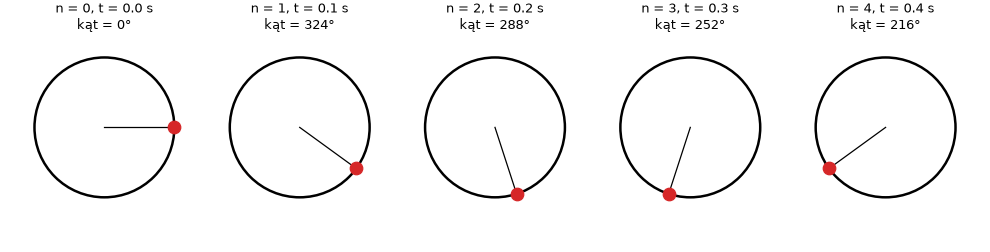

In [4]:
obr_s, klatki_s = 9, 10
kat = 360 * obr_s / klatki_s
print("kąt między zdjęciami:", kat, "° =", kat - 360, "°")
for v in [9, 10, 11]:
    pozorny = (v * 360 / klatki_s + 180) % 360 - 180      # kąt na klatkę sprowadzony do (-180°, 180°]
    print(f"{v} obr/s -> pozornie {pozorny * klatki_s / 360:+.0f} obr/s")

fig, osie = plt.subplots(1, 5, figsize=(11, 2.8))
for n, ax in enumerate(osie):
    fi = np.deg2rad(kat * n)
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, lw=2))
    ax.plot([0, np.cos(fi)], [0, np.sin(fi)], "k-", lw=1)
    ax.plot(np.cos(fi), np.sin(fi), "o", color="C3", ms=10)
    ax.set_title(f"n = {n}, t = {n/10:.1f} s\nkąt = {(kat * n) % 360:.0f}°", fontsize=10)
    ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout(); plt.savefig("zadanie3.png"); plt.show()

## Zadanie 4. Czy pomiar zauważy krótki impuls?

fs = 20 Hz, tc = 0.2: max = 1.00
fs = 20 Hz, tc = 0.213: max = 0.35
fs = 20 Hz, tc = 0.225: max = 0.00
fs = 200 Hz, tc = 0.2: max = 1.00
fs = 200 Hz, tc = 0.213: max = 0.90
fs = 200 Hz, tc = 0.225: max = 1.00


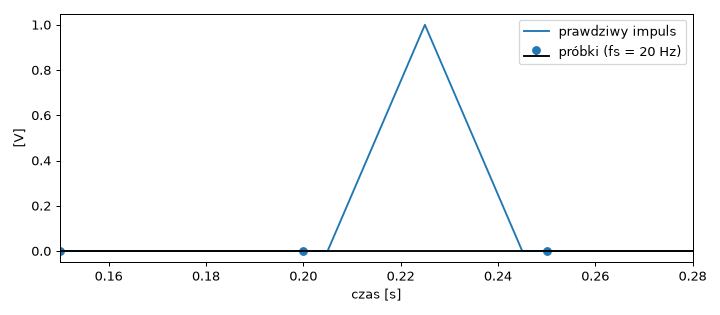

In [5]:
def impuls(t, tc):     # trójkąt o wysokości 1, trwa 40 ms, szczyt w chwili tc
    return np.maximum(1 - np.abs(t - tc) / 0.020, 0)

t_g = np.linspace(0, 0.4, 4001)          # gęsta siatka – tylko do rysowania
for fs in [20, 200]:
    t = np.arange(int(0.4 * fs)) / fs    # chwile pomiaru
    for tc in [0.200, 0.213, 0.225]:
        x = impuls(t, tc)
        print(f"fs = {fs} Hz, tc = {tc}: max = {np.max(x):.2f}")

fs = 20
t = np.arange(int(0.4 * fs)) / fs
tc = 0.225
plt.figure(figsize=(8, 3.5))
plt.plot(t_g, impuls(t_g, tc), label="prawdziwy impuls")
plt.stem(t, impuls(t, tc), basefmt="k-", label="próbki (fs = 20 Hz)")
plt.xlim(0.15, 0.28); plt.xlabel("czas [s]"); plt.ylabel("[V]"); plt.legend()
plt.tight_layout(); plt.savefig("zadanie4.png"); plt.show()

## Zadanie 5. Co robi liczba bitów przetwornika?

A = 0.9, 3 bitów: q = 0.25000, q/2 = 0.12500, największy błąd = 0.12475
A = 0.9, 5 bitów: q = 0.06250, q/2 = 0.03125, największy błąd = 0.03100
A = 0.9, 8 bitów: q = 0.00781, q/2 = 0.00391, największy błąd = 0.00387
A = 1.2, 8 bitów: q = 0.00781, q/2 = 0.00391, największy błąd = 0.23391
próbki trafiające na najwyższy poziom 3-bitowy: [0.76 0.76 0.8  0.8  0.83 0.83 0.86 0.86 0.89 0.89 0.91 0.91 0.92 0.92
 0.93 0.93 0.93]


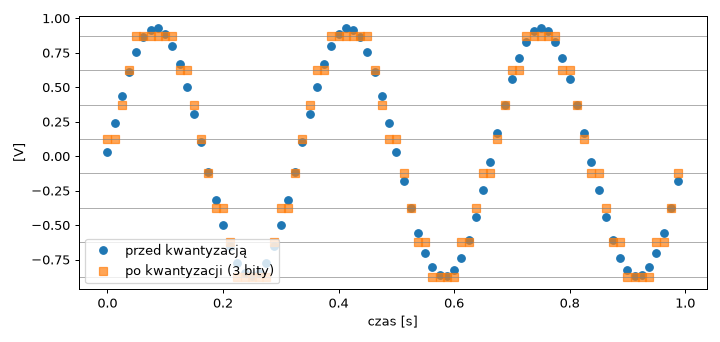

In [6]:
def kwantyzuj(x, B):
    """Przetwornik o zakresie od -1 V do +1 V i B bitach."""
    q = 2 / 2**B                                   # krok kwantyzacji
    k = np.clip(np.floor((x + 1) / q), 0, 2**B - 1)  # numer poziomu
    return -1 + (k + 0.5) * q, q                   # wartość poziomu i krok

fs = 80
t = np.arange(fs) / fs                            # 1 s pomiaru
for A in [0.9, 1.2]:
    x = A * np.sin(2 * np.pi * 3 * t) + 0.03      # próbki [V]
    for B in ([3, 5, 8] if A == 0.9 else [8]):
        xq, q = kwantyzuj(x, B)
        blad = xq - x
        print(f"A = {A}, {B} bitów: q = {q:.5f}, q/2 = {q/2:.5f}, największy błąd = {np.max(np.abs(blad)):.5f}")

x = 0.9 * np.sin(2 * np.pi * 3 * t) + 0.03
xq, q = kwantyzuj(x, 3)
print("próbki trafiające na najwyższy poziom 3-bitowy:", np.round(np.sort(x[xq == xq.max()]), 2))
plt.figure(figsize=(8, 3.8))
plt.plot(t, x, "o", label="przed kwantyzacją")
plt.plot(t, xq, "s", label="po kwantyzacji (3 bity)", alpha=0.7)
for poziom in -1 + (np.arange(8) + 0.5) * q:
    plt.axhline(poziom, color="gray", lw=0.5)
plt.xlabel("czas [s]"); plt.ylabel("[V]"); plt.legend(loc="lower left")
plt.tight_layout(); plt.savefig("zadanie5.png"); plt.show()

## Zadanie 6 (dla chętnych). Czy dwie próbki na okres wystarczą?

fs = 20
  [ 0.5 -0.5  0.5 -0.5  0.5 -0.5]
  [ 0.5 -0.5  0.5 -0.5  0.5 -0.5]
  allclose: True
fs = 25
  [ 0.5    0.105 -0.669  0.978 -0.914  0.5  ]
  [ 0.5   -0.405  0.155  0.155 -0.405  0.5  ]
  allclose: False


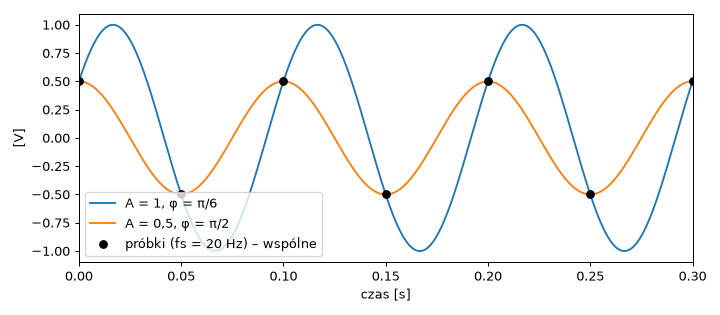

In [7]:
f = 10
for fs in [20, 25]:
    t = np.arange(fs) / fs                     # 1 s pomiaru
    x1 = 1.0 * np.sin(2 * np.pi * f * t + np.pi / 6)   # amplituda 1
    x2 = 0.5 * np.sin(2 * np.pi * f * t + np.pi / 2)   # amplituda 0,5
    print("fs =", fs)
    print(" ", np.round(x1[:6], 3))
    print(" ", np.round(x2[:6], 3))
    print("  allclose:", np.allclose(x1, x2, atol=1e-10))

fs = 20
t = np.arange(fs) / fs
t_g = np.linspace(0, 0.3, 3001)
plt.figure(figsize=(8, 3.5))
plt.plot(t_g, np.sin(2*np.pi*f*t_g + np.pi/6), label="A = 1, φ = π/6")
plt.plot(t_g, 0.5*np.sin(2*np.pi*f*t_g + np.pi/2), label="A = 0,5, φ = π/2")
plt.plot(t, 0.5 * (-1) ** np.arange(fs), "ko", label="próbki (fs = 20 Hz) – wspólne")
plt.xlim(0, 0.3); plt.xlabel("czas [s]"); plt.ylabel("[V]"); plt.legend(loc="lower left")
plt.tight_layout(); plt.savefig("zadanie6.png"); plt.show()

## Zadanie 7 (dla chętnych). Oscyloskop pokazuje ładny sinus. Czy to prawda?

okno 1e-05 s: fs = 1000000000 Sa/s, f_N = 500000000 Hz, wygląda jak 1 kHz: False
okno 0.01 s: fs = 1000000 Sa/s, f_N = 500000 Hz, wygląda jak 1 kHz: True
okno 0.02 s: fs = 500000 Sa/s, f_N = 250000 Hz, wygląda jak 1 kHz: True


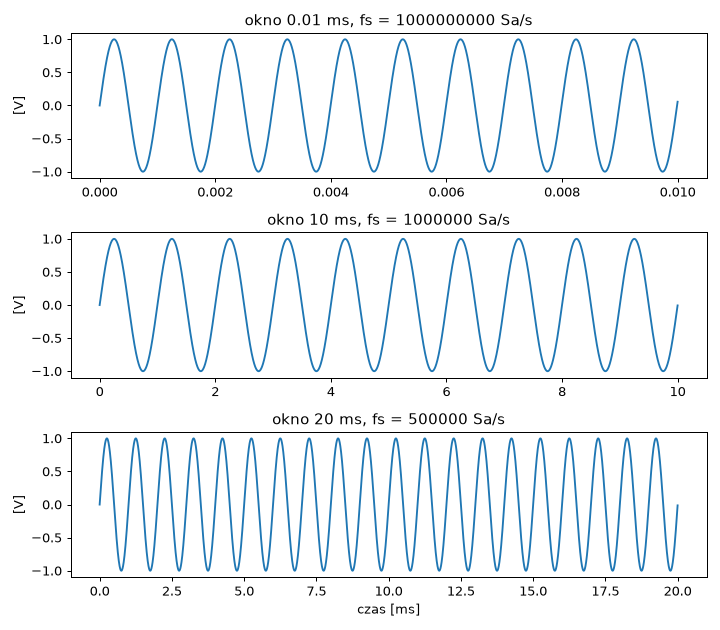

In [8]:
N = 10_000              # tyle próbek mieści pamięć oscyloskopu
fs_max = 1e9            # 1 GSa/s – najszybsze próbkowanie
f = 1.001e6             # generator: 1,001 MHz

fig, osie = plt.subplots(3, 1, figsize=(8, 7))
for ax, okno in zip(osie, [10e-6, 10e-3, 20e-3]):        # okno ekranu = 10 działek
    fs = min(N / okno, fs_max)
    t = np.arange(N) / fs
    x = np.sin(2 * np.pi * f * t)
    alias = np.allclose(x, np.sin(2*np.pi*1000*t), atol=1e-10)
    print(f"okno {okno} s: fs = {fs:.0f} Sa/s, f_N = {fs/2:.0f} Hz, wygląda jak 1 kHz: {alias}")
    ax.plot(t * 1e3, x)
    ax.set_title(f"okno {okno*1e3:g} ms, fs = {fs:.0f} Sa/s")
    ax.set_ylabel("[V]")
osie[-1].set_xlabel("czas [ms]")
plt.tight_layout(); plt.savefig("zadanie7.png"); plt.show()

## Zadanie 8 (dla chętnych). Filtr przed zmniejszeniem fs

bez filtru == sam sinus 2 Hz: True
błąd z filtrem: 0.02


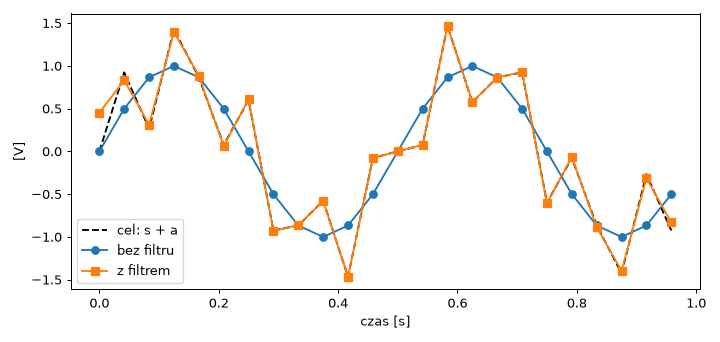

In [9]:
from scipy.signal import resample_poly

t = np.arange(240) / 240                         # 1 s, fs = 240 Hz
s = np.sin(2 * np.pi * 2 * t)                    # 2 Hz
a = 0.6 * np.sin(2 * np.pi * 9 * t)              # 9 Hz – chcemy ją zachować
b = 0.6 * np.sin(2 * np.pi * 15 * t)             # 15 Hz – za szybka dla 24 Hz
x = s + a + b

bez_filtru = x[::10]                 # co dziesiąta próbka: fs = 24 Hz
z_filtrem = resample_poly(x, 1, 10)  # najpierw filtr, potem co dziesiąta

t24 = np.arange(24) / 24
cel = np.sin(2*np.pi*2*t24) + 0.6*np.sin(2*np.pi*9*t24)   # s + a w nowych chwilach
print("bez filtru == sam sinus 2 Hz:", np.allclose(bez_filtru, np.sin(2*np.pi*2*t24), atol=1e-10))
print("błąd z filtrem:", round(np.max(np.abs(z_filtrem - cel)[4:-4]), 3))

plt.figure(figsize=(8, 3.8))
plt.plot(t24, cel, "k--", label="cel: s + a")
plt.plot(t24, bez_filtru, "o-", label="bez filtru")
plt.plot(t24, z_filtrem, "s-", label="z filtrem")
plt.xlabel("czas [s]"); plt.ylabel("[V]"); plt.legend(loc="lower left")
plt.tight_layout(); plt.savefig("zadanie8.png"); plt.show()